# Проект. Исследование стартапов
- Автор: Мактупова Диана
- Дата: 23.12.2025
## Введение

Необходимо помочь заказчикам (финансовой компании, работающей с венчурными инвестициями) понять закономерности финансирования стартапов и оценить перспективы выхода на рынок с покупкой и развитием компаний. Дана  историческая информация о компаниях, объёмах и типах привлечённых инвестиций, а также с дополнительной статистикой по возвратам средств.
Цель проекта — подготовить датасет к работе, исследовать динамику и структуру финансирования стартапов и ответить на вопросы, важные для оценки инвестиционных стратегий.


## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


In [154]:
#Загрузим необходимые для работы библиотеки
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [155]:
#цветовая карта
colorlist =  ['dodgerblue', 'blue', 'mediumblue']
#список типов финансирования
funding_type = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

In [156]:
#Загрузим данные по проекту
df_invest = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
df_returns = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv")

### 1.1. Вывод общей информации

Узнаем объём данных, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных.

In [157]:
#Количество непустых значений в каждом столбце df_invest и тип данных
original_count = df_invest.shape[0]
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [158]:
#Количество пустых значений в каждом столбце df_invest
df_invest.isna().sum()

,0
name,4857
homepage_url,8305
category_list,8817
market,8817
funding_total_usd,4856
status,6170
country_code,10129
state_code,24133
region,10129
city,10972


In [159]:
#Доля пустых значений
round(100*df_invest.isna().mean())

,0
name,9.0
homepage_url,15.0
category_list,16.0
market,16.0
funding_total_usd,9.0
status,11.0
country_code,19.0
state_code,44.0
region,19.0
city,20.0


In [160]:
df_invest

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [161]:
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


Датасет `cb_investments` содержит 54294 строки, при этом, скорее всего, 4856 полностью пустые, необходимо это проверить. Не считая их, пропуски есть в столбцах `homepage_url`, `category_list`, `market`, `status`, `country_code`, `state_code`, `region`,
`city`, `participants`, `founded_at`, `founded_month`, `founded_quarter`, `founded_year` и `mid_funding_at`. Столбцы `founded_month`, `founded_quarter`, `founded_year` вычисляются из столбца `founded_at`. В датасете `cb_returns` пропусков нет.

Названия соответствуют содержанию,  в названии столбцов `market` и `funding_total_usd` присутствуют пробелы, а в названиях `round_A` - `round_H` - большие буквы, их необходимо привести к snake_case. Необходимо обработать типы данных в столбцах с датой и временем: `first_funding_at`, `mid_funding_at`,`last_funding_at`. Поскольку дата основания в исследованиях не участвует, типы данных у`founded_at`,  `founded_month` и `founded_quarter` мы менять не будем. Также привести к числовому формату столбец `funding_total_usd`, привести к целочисленному значению столбцы `funding_rounds`, `participants`,`founded_year`,  Также нужно оптимизировать размерность.

### 1.2. Предобработка данных


In [162]:
# В названии столбцов market и funding_total_usd присутствуют пробелы в начале.
# Избавимся от них. Также столбцы round_A - round_H надо будет привести к стилю snake_case.
df_invest.columns = df_invest.columns.str.lower().str.strip()
df_invest.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_a', 'round_b',
       'round_c', 'round_d', 'round_e', 'round_f', 'round_g', 'round_h'],
      dtype='object')

In [163]:
#Уберём в столбце `funding_total_usd` выделение разрядов и приведём его к числовому типу.
df_invest['funding_total_usd']=df_invest['funding_total_usd'].str.replace(',','')
df_invest['funding_total_usd']=pd.to_numeric(df_invest['funding_total_usd'], downcast='float',errors ='coerce')
df_invest['funding_total_usd'].head(15)

,funding_total_usd
0,90000000.0
1,2000000.0
2,9000000.0
3,7700000.0
4,540000.0
5,19000000.0
6,12000000.0
7,8700000.0
8,6000000.0
9,3500000.0


In [164]:
#Обработаем типы данных в столбцах, которые хранят значения даты и времени
for column in ['first_funding_at','mid_funding_at','last_funding_at']:
    df_invest[column] = pd.to_datetime(df_invest[column], format ='%Y-%m-%d',errors = 'coerce')
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  49437 non-null  object        
 1   homepage_url          45989 non-null  object        
 2   category_list         45477 non-null  object        
 3   market                45477 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                48124 non-null  object        
 6   country_code          44165 non-null  object        
 7   state_code            30161 non-null  object        
 8   region                44165 non-null  object        
 9   city                  43322 non-null  object        
 10  funding_rounds        49438 non-null  float64       
 11  participants          30473 non-null  float64       
 12  founded_at            38554 non-null  object        
 13  founded_month   

In [165]:
# Cделаем столбец `year` индексом всего датасета`cb_returns`
df_returns = df_returns.set_index('year')


In [166]:
#Обработаем текстовые данные. Пропуски в текстовых столбцах заполним заглушками там, где это понадобится
for column in ['homepage_url','category_list', 'market','status','region','city']:
    df_invest[column]=df_invest[column].str.lower().str.strip()
for column in ['name','country_code', 'state_code']:
    df_invest[column]=df_invest[column].str.upper().str.strip()
for column in ['name', 'homepage_url','category_list','market','status','country_code', 'state_code', 'region', 'city']:
    df_invest[column]=df_invest[column].fillna('Unknown')
df_invest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  54294 non-null  object        
 1   homepage_url          54294 non-null  object        
 2   category_list         54294 non-null  object        
 3   market                54294 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                54294 non-null  object        
 6   country_code          54294 non-null  object        
 7   state_code            54294 non-null  object        
 8   region                54294 non-null  object        
 9   city                  54294 non-null  object        
 10  funding_rounds        49438 non-null  float64       
 11  participants          30473 non-null  float64       
 12  founded_at            38554 non-null  object        
 13  founded_month   

In [167]:
#Обработаем явные дубликаты
count_explicit_duplicates=df_invest.duplicated().sum()
df_invest.drop_duplicates(inplace=True)

In [168]:
#Проверим неявные дубликаты
count_implicit_duplicates=df_invest.duplicated(subset = ['name','homepage_url']).sum()
df_invest.sort_values(by = 'funding_total_usd', ascending = False).drop_duplicates(subset = ['name','homepage_url'], keep = 'first', inplace=True)

In [169]:
#Узнаем количество пропусков в funding_total_usd
df_invest['funding_total_usd']=df_invest['funding_total_usd'].astype('float64')
df_invest['funding_total_usd'].isna().sum()

np.int64(8532)

In [170]:
#Заполним пропуски в funding_total_usd суммированием по всем источникам, а после этого проверим, изменилось ли количество строк, не содержащих информацию об общем финансировании
def sum_up_row(row):
    return row.sum()
df_invest['funding_total_usd']=df_invest['funding_total_usd'].fillna(df_invest[['seed', 'venture', 'equity_crowdfunding','undisclosed','convertible_note','debt_financing','angel','grant','private_equity','post_ipo_equity','post_ipo_debt','secondary_market','product_crowdfunding']].apply(sum_up_row,axis=1))
count_zero_funding = df_invest['funding_total_usd'].loc[df_invest['funding_total_usd']==0].count()
count_zero_funding

np.int64(8532)

In [171]:
#проверим долю пропусков
round(100*count_zero_funding/df_invest.shape[0],2)

np.float64(17.26)

In [172]:
#Создадим логическую маску, отсеивающую эти записи
filtered_df_nonzero_funding = df_invest[df_invest['funding_total_usd']!=0]
filtered_df_nonzero_funding.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40907 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40907 non-null  object        
 1   homepage_url          40907 non-null  object        
 2   category_list         40907 non-null  object        
 3   market                40907 non-null  object        
 4   funding_total_usd     40907 non-null  float64       
 5   status                40907 non-null  object        
 6   country_code          40907 non-null  object        
 7   state_code            40907 non-null  object        
 8   region                40907 non-null  object        
 9   city                  40907 non-null  object        
 10  funding_rounds        40907 non-null  float64       
 11  participants          27331 non-null  float64       
 12  founded_at            32201 non-null  object        
 13  founded_month        

In [173]:
#Узнаем количество пропусков в 'mid_funding_at'
count_na_mid_funding=df_invest['mid_funding_at'].isna().sum()
count_na_mid_funding

np.int64(19151)

In [174]:
#Заполним пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.
filtered_df_nonzero_funding.loc[:,'mid_funding_at']=filtered_df_nonzero_funding.loc[:,'mid_funding_at'].fillna(filtered_df_nonzero_funding['first_funding_at']+(filtered_df_nonzero_funding['last_funding_at']-filtered_df_nonzero_funding['first_funding_at'])/2)

In [175]:
count_mid_nat_final = filtered_df_nonzero_funding['mid_funding_at'].isna().sum()
count_mid_nat_final

np.int64(1)

In [176]:
filtered_df_nonzero_funding[['first_funding_at','mid_funding_at','last_funding_at']].loc[filtered_df_nonzero_funding['mid_funding_at'].isna()]

,first_funding_at,mid_funding_at,last_funding_at
33041,NaT,NaT,2014-09-25


Остался 1 пропуск, причина пропусков - не было даты первого финансирования.

In [177]:
#Оценим пдолю пропусков
na_share=round(100*filtered_df_nonzero_funding.isna().mean())
na_share

,0
name,0.0
homepage_url,0.0
category_list,0.0
market,0.0
funding_total_usd,0.0
status,0.0
country_code,0.0
state_code,0.0
region,0.0
city,0.0


In [178]:
print(f'''
    1.Удалено {count_explicit_duplicates} явных дубликатов, что составляет {round(100*count_explicit_duplicates/original_count,2)}% от изначального количества строк
    2.Удалено {count_implicit_duplicates} неявных дубликатов, что составляет {round(100*count_implicit_duplicates/original_count,2)}% от изначального количества строк
    3.Отфильтровано {count_zero_funding} строк, не содержащих финансовую информацию, что составляет {round(100*count_zero_funding/original_count,2)}% от изначального количества строк
    4.Заполнено {count_na_mid_funding - count_mid_nat_final} пропусков в столбце "mid_funding_at", остался незаполненным {count_mid_nat_final} пропуск
    5.Осталось {filtered_df_nonzero_funding.shape[0]} записей, это {round(100*filtered_df_nonzero_funding.shape[0]/original_count,2)}% от изначального количества строк ''')


    1.Удалено 4855 явных дубликатов, что составляет 8.94% от изначального количества строк
    2.Удалено 14 неявных дубликатов, что составляет 0.03% от изначального количества строк
    3.Отфильтровано 8532 строк, не содержащих финансовую информацию, что составляет 15.71% от изначального количества строк
    4.Заполнено 19150 пропусков в столбце "mid_funding_at", остался незаполненным 1 пропуск
    5.Осталось 40907 записей, это 75.34% от изначального количества строк 


### Промежуточный вывод
В ходе предобработки была проделана следующая работа:
- Удалено 4855 явных дубликатов и 14 неявных дубликатов, что составляет 8.94% и 0.03% от изначального количества строк.
- Удалены пробелы в названии столбцов `market` и `funding_total_usd`. Названия столбцов `round_A` - `round_H` приведены к стилю snake_case.
- Столбец `funding_total_usd` приведён к числовому типу. Была попытка заполнить пропуски суммой инвестиций из всех источников, однако для всех строк эта сумма оказалась нулевой. Отфильтровано 8532 строк, не содержащих финансовую информацию, что составляет 15.71% от изначального количества строк.
- Пропуски в текстовых столбцах были заполнены значением "Unknown".
- Данные в столбцах `first_funding_at`,`mid_funding_at` и `last_funding_at` были приведены к типу данных `datetime64[ns]`.
- Было заполнено 19150 пропусков в столбце `mid_funding_at` серединой интервала между `last_funding_at` и `first_funding_at`. Остался незаполненным 1 пропуск.
- В результате осталось 33% пропусков в столбце `participants`, 21% в столбцах `founded_at`,`founded_month`,`founded_quarter`, `founded_year`, однако они не повлияют на предстоящие исследования, поэтому могут быть оставлены.
- После преобразований осталось 40907 записей. Этого достаточно для решения задач проекта.

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируем соотношение этих групп, создав два графика:

* По количеству компаний: Покажем, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразим, какую долю от общего объёма привлечённых средств получила каждая группа.


In [179]:
def categorize_funding (df):
    if df['funding_rounds']==1:
        return 'Единичное финансирование'
    elif (df['last_funding_at']-df['first_funding_at'])<=pd.to_timedelta('365 days'):
        return 'Срок финансирования до года'
    else:
        return 'Срок финансирования более года'

In [180]:
filtered_df_nonzero_funding.insert(loc=40, column='funding_category', value=filtered_df_nonzero_funding.apply(categorize_funding, axis=1))

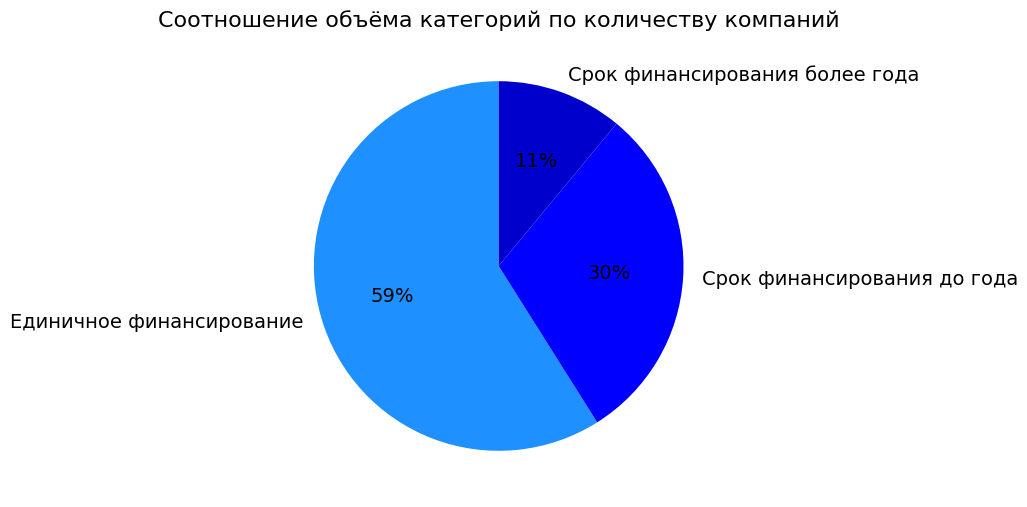

In [181]:
plt.figure(figsize=(10,6))
count_groupped = filtered_df_nonzero_funding.loc[:,'funding_category'].value_counts()
count_groupped.plot.pie(startangle = 90, autopct='%1.f%%',textprops={'fontsize':14}, labels = ['Единичное финансирование', 'Срок финансирования до года', 'Срок финансирования более года'],
                        colors = colorlist)
plt.title('Соотношение объёма категорий по количеству компаний',fontdict={'fontsize':16})
plt.ylabel('')
plt.show()

In [182]:
funding_sum = filtered_df_nonzero_funding.groupby('funding_category')['funding_total_usd'].sum()
round(funding_sum/1000000000,2)

,funding_total_usd
funding_category,
Единичное финансирование,199.30
Срок финансирования более года,402.74
Срок финансирования до года,48.89


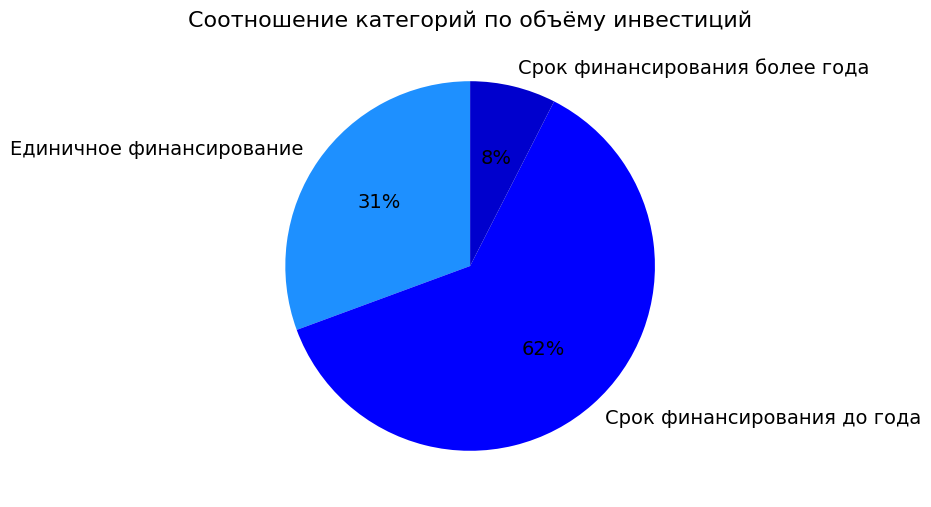

In [183]:
plt.figure(figsize=(10,6))
funding_sum.plot.pie(startangle = 90, autopct='%1.f%%',textprops={'fontsize':14}, labels = ['Единичное финансирование', 'Срок финансирования до года', 'Срок финансирования более года'],colors = colorlist)
plt.title('Соотношение категорий по объёму инвестиций',fontdict={'fontsize':16})
plt.ylabel('')
plt.show()

59% компаний получили единичное финансирование, 30% финансировались меньше года и только 11% больше года. При этом по объёму больше всего, а именно 62% (или 402.7 млрд. долларов) инвестиций вложено в категорию компаний, которые финансировались меньше года, 31% являются единичным финансированием (199.3 млрд. долларов), и только 8% (48.9 млрд. долларов) инвестиций вложены в компании, которые финансировались больше года.

### 2.2 Выделение средних и нишевых сегментов рынка
Компании указывают свой сегмент рынка в столбце `market`. Рассчитаем, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесём к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесём к средним, а сегменты до 35 компаний отнесём к нишевым. Рассчитаем, сколько сегментов попадает в каждую из категорий.

Построим график распределения количества компаний в сегментах и отобразим на нём разделение на нишевые и средние сегменты.

In [184]:
#категоризируем
df_market = filtered_df_nonzero_funding.loc[:,'market'].value_counts().reset_index().rename(columns={'market': 'market', 'count': 'amount'})
def categorize_market(df):
    if df['amount'] < 35:
        return 'niche'
    elif 35 <= df['amount'] <= 120:
        return 'mid'
    else:
        return 'mass'
df_market['segment'] = df_market.apply(categorize_market, axis = 1)
df_market

,market,amount,segment
0,software,4812,mass
1,biotechnology,3590,mass
2,Unknown,2503,mass
3,mobile,2344,mass
4,e-commerce,1866,mass
...,...,...,...
390,law enforcement,1,niche
391,real estate investors,1,niche
392,business productivity,1,niche
393,musicians,1,niche


In [185]:
market_category = df_market['segment'].value_counts().sort_values()
market_category

,count
segment,
mass,49
mid,57
niche,289


In [186]:
market_share = round(100*market_category/df_market.shape[0])
market_share

,count
segment,
mass,12.0
mid,14.0
niche,73.0


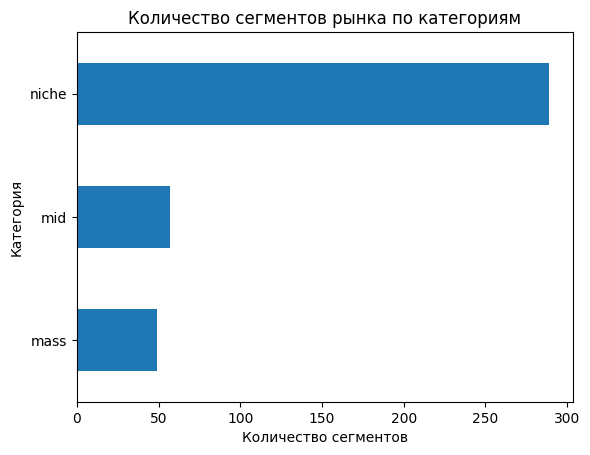

In [187]:
market_category.plot.barh()
plt.title("Количество сегментов рынка по категориям")
plt.xlabel('Количество сегментов')
plt.ylabel('Категория')
plt.show()

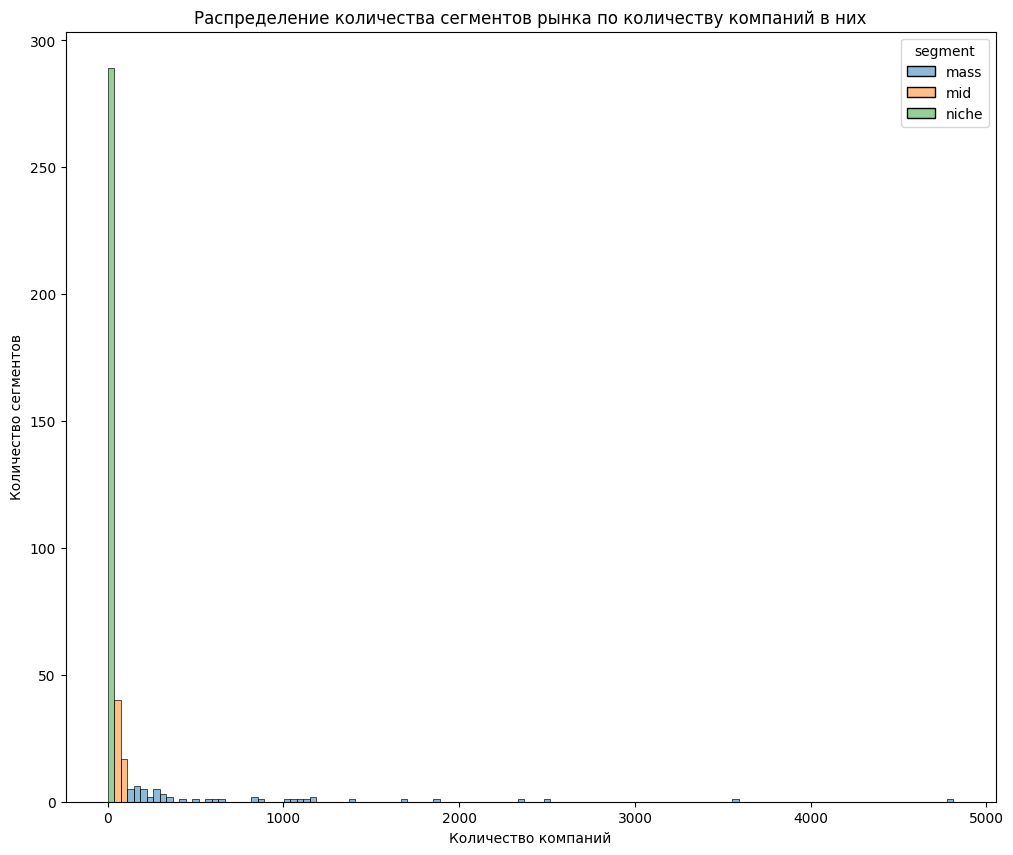

In [188]:
plt.figure(figsize=(12,10))
#распределение в общем
sns.histplot(data=df_market,  x='amount', bins=130, kde=False, legend=True, hue ='segment')
plt.title("Распределение количества сегментов рынка по количеству компаний в них")
plt.xlabel('Количество компаний')
plt.ylabel('Количество сегментов')
plt.show()

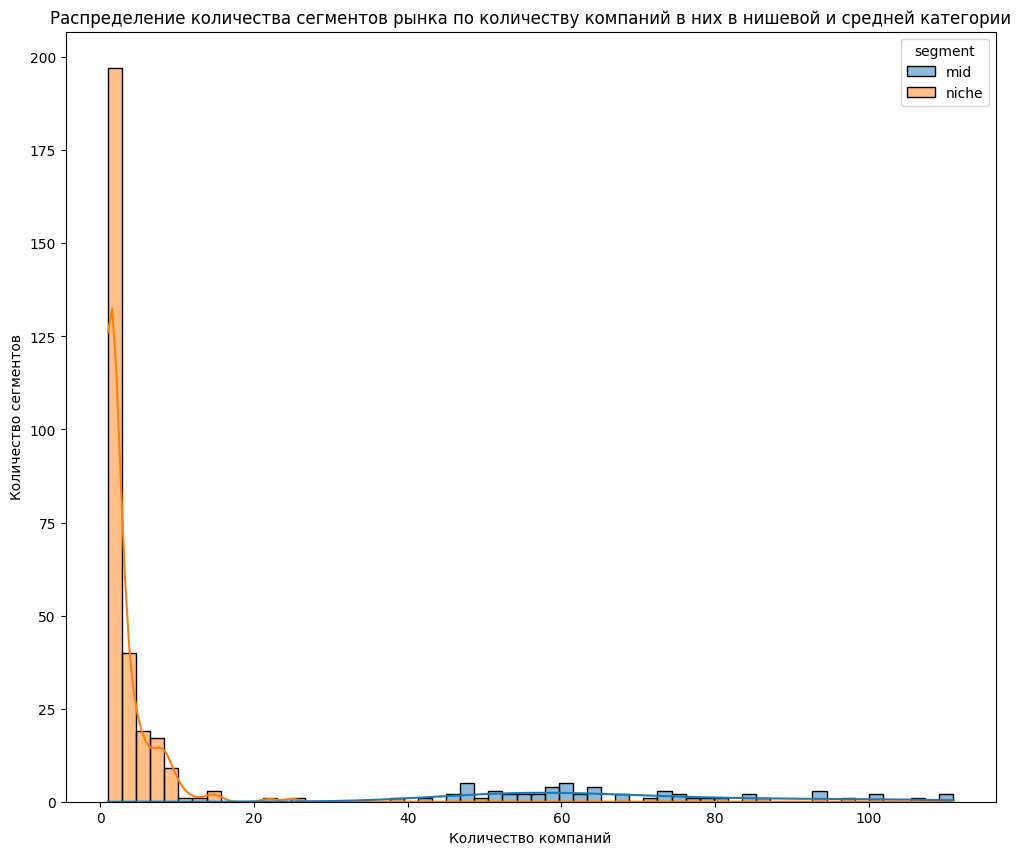

In [189]:
plt.figure(figsize=(12,10))
#распределение в общем
sns.histplot(data=df_market.loc[(df_market['segment']=='niche')|(df_market['segment']=='mid')],  bins=60, kde=True, legend=True, x='amount', hue ='segment')
plt.title("Распределение количества сегментов рынка по количеству компаний в них в нишевой и средней категории")
plt.xlabel('Количество компаний')
plt.ylabel('Количество сегментов')
plt.show()

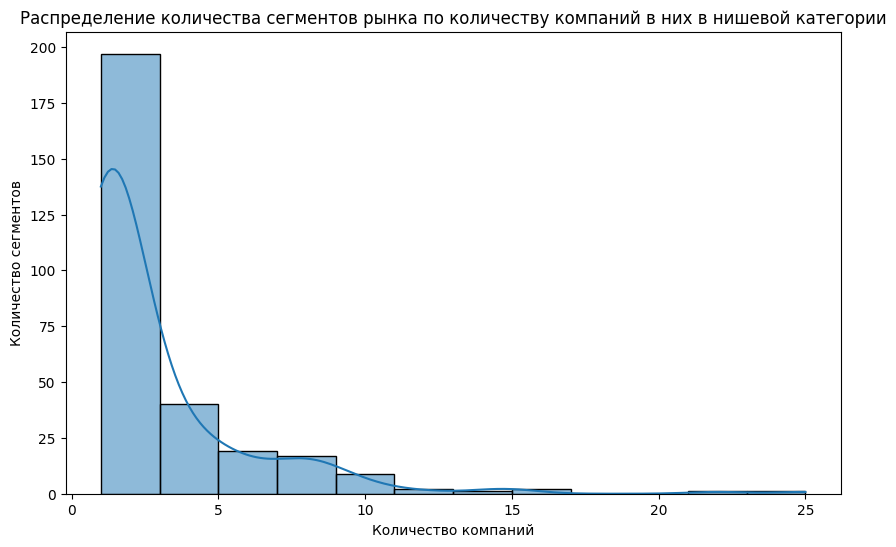

In [190]:
plt.figure(figsize=(10,6))
#распределение в нишевых
sns.histplot(data=df_market.loc[df_market['segment']=='niche'],  bins=12, kde=True, legend=False)
plt.title("Распределение количества сегментов рынка по количеству компаний в них в нишевой категории")
plt.xlabel('Количество компаний')
plt.ylabel('Количество сегментов')
plt.show()

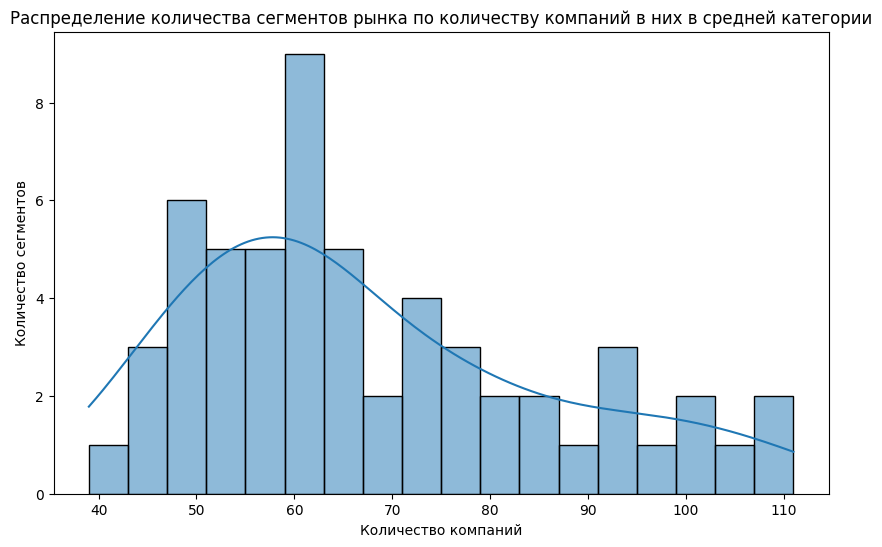

In [191]:
plt.figure(figsize=(10,6))
#распределение в средних
sns.histplot(data=df_market.loc[df_market['segment']=='mid'],  bins=18, kde=True, legend=False)
plt.title("Распределение количества сегментов рынка по количеству компаний в них в средней категории")
plt.xlabel('Количество компаний')
plt.ylabel('Количество сегментов')
plt.show()

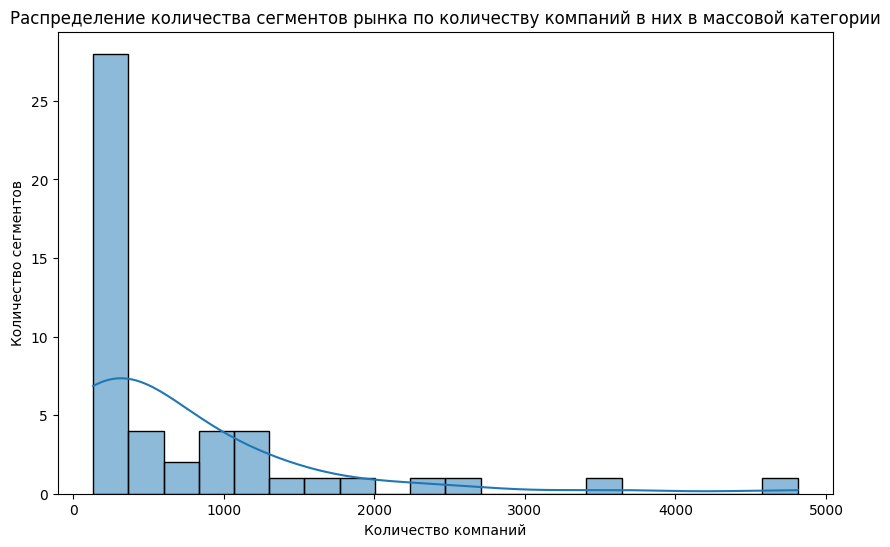

In [192]:
plt.figure(figsize=(10,6))
#распределение в массовых
sns.histplot(data=df_market.loc[df_market['segment']=='mass'],  bins=20, kde=True, legend=False)
plt.title("Распределение количества сегментов рынка по количеству компаний в них в массовой категории")
plt.xlabel('Количество компаний')
plt.ylabel('Количество сегментов')
plt.show()

Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполним с учётом этой замены.


In [193]:
df_joined = filtered_df_nonzero_funding.merge(df_market[['market','segment']], on='market')
for i in range(df_joined.shape[0]):
    if df_joined.loc[i,'segment']=='niche':
        df_joined.loc[i, 'market']='niche'
    elif df_joined.loc[i,'segment']=='mid':
        df_joined.loc[i, 'market']='mid'
df_joined

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,round_a,round_b,round_c,round_d,round_e,round_f,round_g,round_h,funding_category,segment
0,HARVARD UNIVERSITY,http://harvard.edu,|education|,education,90000000.0,operating,USA,MA,boston,cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,mass
1,UNIVERSITY OF NEW BRUNSWICK,http://www.unb.ca,Unknown,Unknown,2000000.0,operating,Unknown,Unknown,Unknown,Unknown,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,mass
2,DUPONT,http://www.dupont.com,|business services|agriculture|automotive|inve...,mid,9000000.0,operating,USA,DE,"wilmington, delaware",wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,mid
3,UNIVERSITY OF MICHIGAN,http://www.umich.edu/,|education|,education,7700000.0,operating,USA,MI,detroit,ann arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Срок финансирования до года,mass
4,CASE WESTERN RESERVE UNIVERSITY,http://www.case.edu,|education|,education,540000.0,operating,USA,OH,cleveland,cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,mass
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40902,RIVERSILICA,http://riversilica.com,Unknown,Unknown,1500000.0,operating,IND,Unknown,bangalore,bangalore,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,mass
40903,SOUTHGOBI RESOURCES,http://southgobi.com,|mining technologies|,niche,9000000.0,operating,CAN,BC,vancouver,vancouver,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,niche
40904,DIGIBYTE,http://digibyte.co,Unknown,Unknown,250000.0,operating,USA,CA,los angeles,santa monica,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,mass
40905,XELTIS,http://xeltis.com,Unknown,Unknown,34000000.0,operating,CHE,Unknown,zurich,zürich,...,0.0,34000000.0,0.0,0.0,0.0,0.0,0.0,0.0,Единичное финансирование,mass


Всего в датасете представлено 395 сегмента рынка, 289 из них являются нишевыми, что составляет 73%. Количество средних и массовых рынков не сильно отличаются между собой: 57 и 49, что составляет 14% и 12% от общего количества соответственно.
У количества компаний в сегменте рынка ярко выраженное правоасимметричное распределение. В значительной части сегментов находятся 1-2 компании. Если рассматривать распределение отдельно в нишевых, массовых и средних сегментах, нишевые и массовые имеют правоассиметричное распределение, а средние - ближе к нормальному распределению с небольшим правым хвостом. В столбце `market` нишевые и средние сегменты заменены на значения `niche` и `mid`.

Основная часть компаний сконцентрирована в одном массовом сегменте, существенная доля приходится на нишевые рынки. Такой разброс указывает на высокую диверсификацию стартап-рынка

## Шаг 3. Работа с выбросами и анализ
### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажем интервал, в котором лежат типичные значения.


<Axes: xlabel='funding_total_usd'>

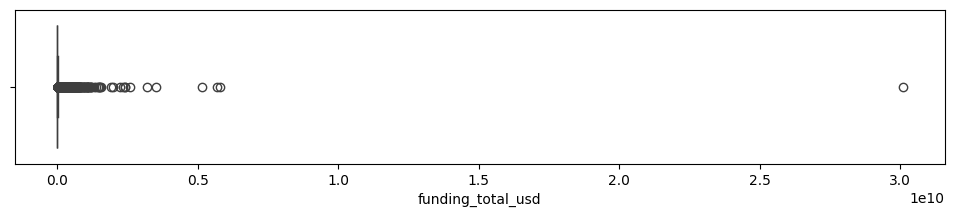

In [194]:
#посмотрим на выбросы
plt.figure(figsize=(12,2))
sns.boxplot(data=df_joined['funding_total_usd'], orient = 'h')

<Axes: xlabel='funding_total_usd'>

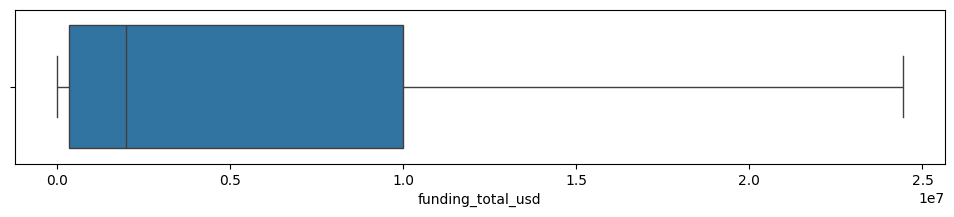

In [195]:
#посмотрим без выбросов
plt.figure(figsize=(12,2))
sns.boxplot(data=df_joined['funding_total_usd'], orient = 'h', showfliers=False)

In [196]:
max_norm_funding=df_joined['funding_total_usd'].quantile(0.75)+1.5*(df_joined['funding_total_usd'].quantile(0.75)-df_joined['funding_total_usd'].quantile(0.25))
median_funding = df_joined['funding_total_usd'].median()
share_fliers =round(100*df_joined['funding_total_usd'].loc[df_joined['funding_total_usd']>max_norm_funding].count()/df_joined.shape[0])
print (max_norm_funding, median_funding, share_fliers)

24475000.0 2000000.0 13


Определим компании с аномальным объёмом общего финансирования — используем метод IQR отдельно по каждому сегменту.
Определим сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведем топ таких сегментов.

In [197]:
market_list=df_joined['market'].unique().tolist()
share_fliers_list = []
index_list = []
for market in market_list:
    iqr = df_joined['funding_total_usd'].loc[df_joined['market']==market].quantile(0.75)-df_joined['funding_total_usd'].loc[df_joined['market']==market].quantile(0.25)
    max_border = df_joined['funding_total_usd'].loc[df_joined['market']==market].quantile(0.75)+1.5*iqr
    min_border = df_joined['funding_total_usd'].loc[df_joined['market']==market].quantile(0.25)-1.5*iqr
    index_list.extend(df_joined.loc[(df_joined['market']==market)&(df_joined['funding_total_usd']>=min_border)&(df_joined['funding_total_usd']<=max_border)].index.tolist())
    share = round(100*df_joined.loc[(df_joined['market']==market)&
                                   ((df_joined['funding_total_usd']<min_border)|
                                   (df_joined['funding_total_usd']>max_border))].groupby('market')['funding_total_usd'].count()/df_joined.loc[(df_joined['market']==market)].shape[0],2)
    share_fliers_list.append(float(share))
fliers_data = {
    'market': market_list,
    'share_fliers': share_fliers_list}
df_fliers = pd.DataFrame(fliers_data)
df_fliers = df_fliers.sort_values(by='share_fliers', ascending = False).head(10).sort_values(by ='share_fliers')
df_fliers=df_fliers.set_index('market')
df_fliers

/tmp/ipykernel_747/3709665587.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  share_fliers_list.append(float(share))
/tmp/ipykernel_747/3709665587.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  share_fliers_list.append(float(share))
/tmp/ipykernel_747/3709665587.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  share_fliers_list.append(float(share))
/tmp/ipykernel_747/3709665587.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  share_fliers_list.append(float(share))
/tmp/ipykernel_747/3709665587.py:12: FutureWarning: Calling float on a single element Series is deprecated and will 

,share_fliers
market,
niche,15.90
video,15.96
technology,15.97
photography,16.18
saas,16.18
cloud computing,16.45
search,16.49
consulting,16.62
entertainment,16.67


In [198]:
mask_index = False
for i in index_list:
    mask_index = mask_index|(df_joined.index==i)

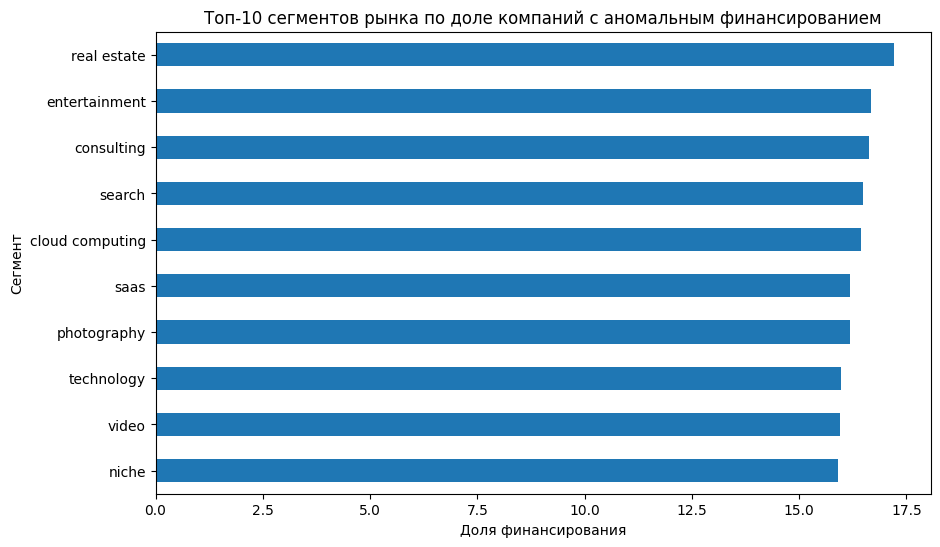

In [199]:
df_fliers.plot.barh(legend = False, figsize=(10,6))
plt.title("Топ-10 сегментов рынка по доле компаний с аномальным финансированием")
plt.xlabel('Доля финансирования')
plt.ylabel('Сегмент')
plt.show()

Типичные значения для финансирования 1 компании в целом - до 24,5 миллионов долларов, все что выше - можно считать выбросами. Всего доля компаний, на инвестиции которым был выделен аномальный объём финансов - 12% от общего количества компаний. В среднем на одну компанию выделяется 2 миллиона долларов (это медиана). Наибольшая доля аномального финансирования в следующих сегментах рынка: "real estate", "entertainment", "consulting" (17.2%, 16.67% и 16.62% соответственно).

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверим по датасету, можно ли считать, что нам предоставили полные данные за 2014 год. Затем исключим из датасета компании, которые мы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставим в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [200]:
mask_2014=(df_joined['first_funding_at'].dt.year == 2014)|(df_joined['mid_funding_at'].dt.year == 2014)|(df_joined['last_funding_at'].dt.year == 2014)
print(f'За 2014 год было финансировано {df_joined.loc[mask_2014].shape[0]} компаний')
max_first= df_joined['first_funding_at'].loc[mask_2014].dt.month.max()
max_mid=df_joined['mid_funding_at'].loc[mask_2014].dt.month.max()
max_last = df_joined['last_funding_at'].loc[mask_2014].dt.month.max()
min_first= df_joined['first_funding_at'].loc[mask_2014].dt.month.min()
min_mid=df_joined['mid_funding_at'].loc[mask_2014].dt.month.min()
min_last = df_joined['last_funding_at'].loc[mask_2014].dt.month.min()
print(f'''
Последний месяц первого финансирования {max_first}, среднего {max_mid}, последнего {max_last} за 2014 год
Первый месяц первого финансирования {min_first}, среднего {min_mid}, последнего {min_last} за 2014 год''')

За 2014 год было финансировано 11915 компаний

Последний месяц первого финансирования 12.0, среднего 12.0, последнего 12 за 2014 год
Первый месяц первого финансирования 1.0, среднего 1.0, последнего 1 за 2014 год


За 2014 год представлены данные о 11915 компаниях, есть данные с января по декабрь. Этого достаточно, чтобы считать данные за этот год полными.

In [201]:
#фильтрация
years_df = (df_joined.groupby(df_joined['mid_funding_at'].dt.year)['funding_rounds'].sum()>=50).reset_index().rename(columns = {'mid_funding_at':'year'})
years_filter = years_df['year'].loc[years_df['funding_rounds']==True].tolist()
mask_years = False
for y in years_filter:
     mask_years = mask_years|(df_joined['mid_funding_at'].dt.year==y)
df_filtered= df_joined.loc[mask_index&mask_years]
df_filtered.shape[0]

35616

Итого после фильтрации у нас остались данные о 35616 компаниях

### 3.3. Анализ типов финансирования по объёму и популярности

Построим график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Также построим график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравним графики и выделим часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

In [202]:
sum_funding = []
sum_share = []
count_funding = []
count_share = []
for i in funding_type:
    sum_funding.append(df_filtered[i].sum())
    sum_share.append(round(100*df_filtered[i].sum()/df_filtered['funding_total_usd'].sum(),2))
    count_funding.append(df_filtered[i].loc[df_filtered[i]>0].count())
    count_share.append(round(100*df_filtered[i].loc[df_filtered[i]>0].count()/df_filtered['funding_total_usd'].count(),2))
funding_dict = {'funding_type': funding_type,
                'sum': sum_funding,
                'sum_share': sum_share,
                'count': count_funding,
                'count_share': count_share}
funding_df = pd.DataFrame(funding_dict).set_index('funding_type')
funding_df

,sum,sum_share,count,count_share
funding_type,,,,
seed,9.440872e+09,5.85,13383,37.58
venture,1.291684e+11,79.98,18835,52.88
equity_crowdfunding,2.379606e+08,0.15,515,1.45
undisclosed,2.138552e+09,1.32,817,2.29
convertible_note,5.660394e+08,0.35,521,1.46
debt_financing,8.178503e+09,5.06,3266,9.17
angel,2.482464e+09,1.54,2940,8.25
grant,1.978849e+09,1.23,1003,2.82
private_equity,4.846109e+09,3.00,635,1.78


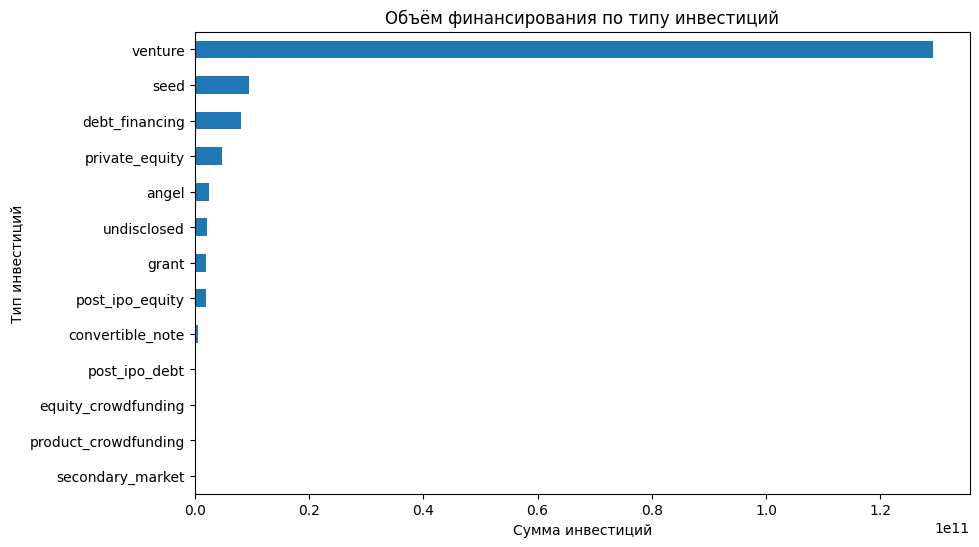

In [203]:
funding_df['sum'].sort_values().plot.barh(legend = False, figsize=(10,6))
plt.title("Объём финансирования по типу инвестиций")
plt.xlabel('Сумма инвестиций')
plt.ylabel('Тип инвестиций')
plt.show()

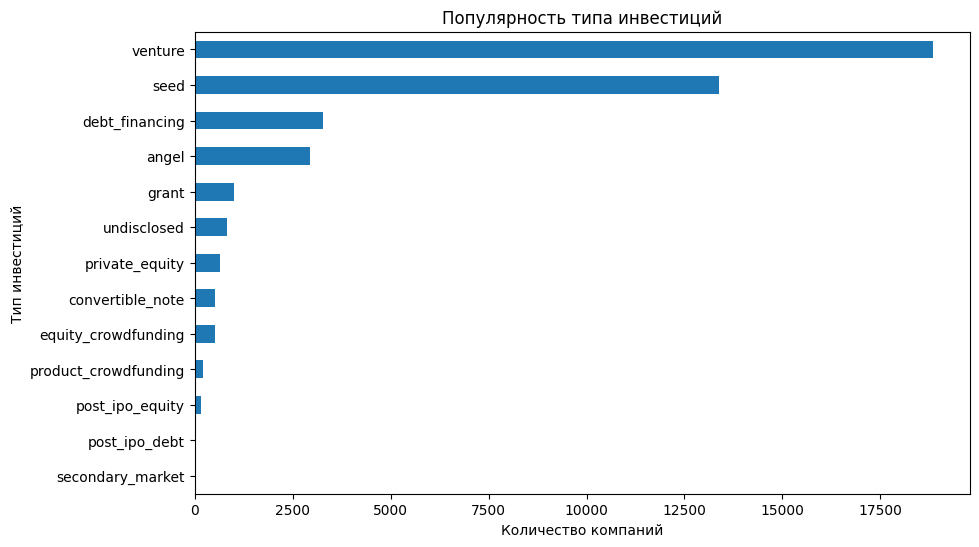

In [204]:
funding_df['count'].sort_values().plot.barh(legend = False, figsize=(10,6))
plt.title("Популярность типа инвестиций")
plt.xlabel('Количество компаний')
plt.ylabel('Тип инвестиций')
plt.show()

Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

In [205]:
sum_return = []
for i in funding_type:
    sum_return.append(df_returns[i].sum())
funding_dict_return = {'funding_type': funding_type,
                'sum': sum_return}
funding_df_return = pd.DataFrame(funding_dict_return).set_index('funding_type').sort_values('sum')
total_return = funding_df_return['sum'].sum()
funding_df_return['share']=round(100*funding_df_return['sum']/total_return)
funding_df_return

,sum,share
funding_type,,
grant,0.00,0.0
product_crowdfunding,1.86,0.0
equity_crowdfunding,3.83,0.0
secondary_market,5.20,0.0
convertible_note,34.79,0.0
post_ipo_debt,91.03,0.0
undisclosed,730.88,1.0
post_ipo_equity,1104.96,2.0
angel,1509.23,3.0


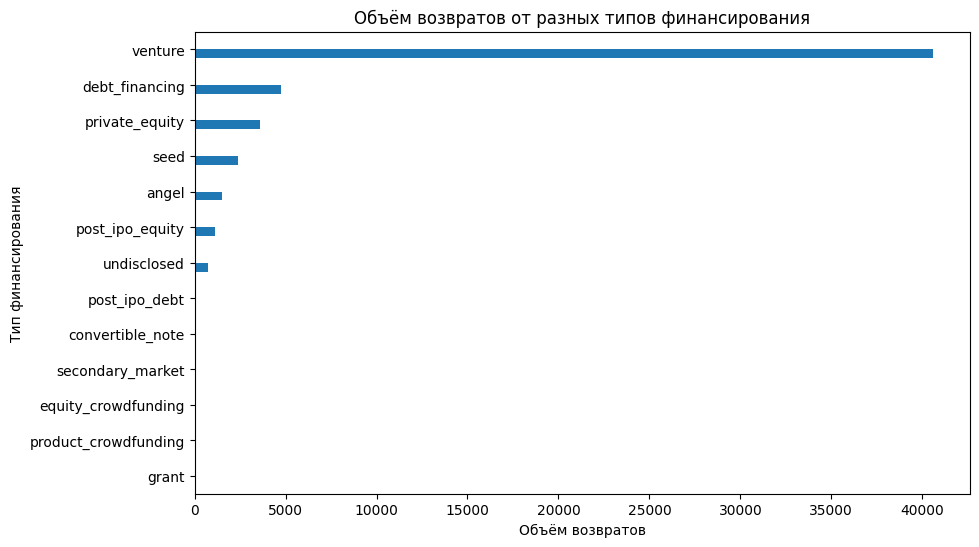

In [206]:
funding_df_return.plot.barh(legend = False, figsize=(10,6))
plt.title("Объём возвратов от разных типов финансирования")
plt.xlabel('Объём возвратов')
plt.ylabel('Тип финансирования')
plt.show()

По большей части, инвестиции является венчурным - к этому типу относится 80% от общего объёма инвестиций. Также это самый популярный тип инвестиций - больше половины компаний имеют инвестиции этого типа. Возвраты соответственно тоже по большей части идут от венчурных инвестиций (74% объёма возвратов венчурные). На 2 месте по популярности являются инвестиции на посевной стадии, 38% компаний имеют такие инвестиции. Хотя по объёму инвестиций этот тип финансирования тоже на 2 месте, это всего 6% от общего объёма инвестиций.  

По объёму возврата на 2 месте стоят возвраты от долгового финансирования - 9% от общего объёма возвратов относятся к этому типу. На третьем месте возвраты от частных вложений - 7% от общего объёма возвратов.

Сумма инвестиций в виде прямых вложений занимает по объёму 4-ое место, однако по популярности этот тип инвестицйий стоит на 7 месте, такой тип встречается в 2% компаний. Та же ситуация с суммой финансирования после IPO. По объёму этот тип стоит на 8 месте, а по популярности на 11-ом. Гранты стоят на 5-ом месте по популярности, но при этом по объёму на 7-ом.


## Шаг 4. Анализ динамики
### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитаем для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы построим графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

На основе полученных данных ответим на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

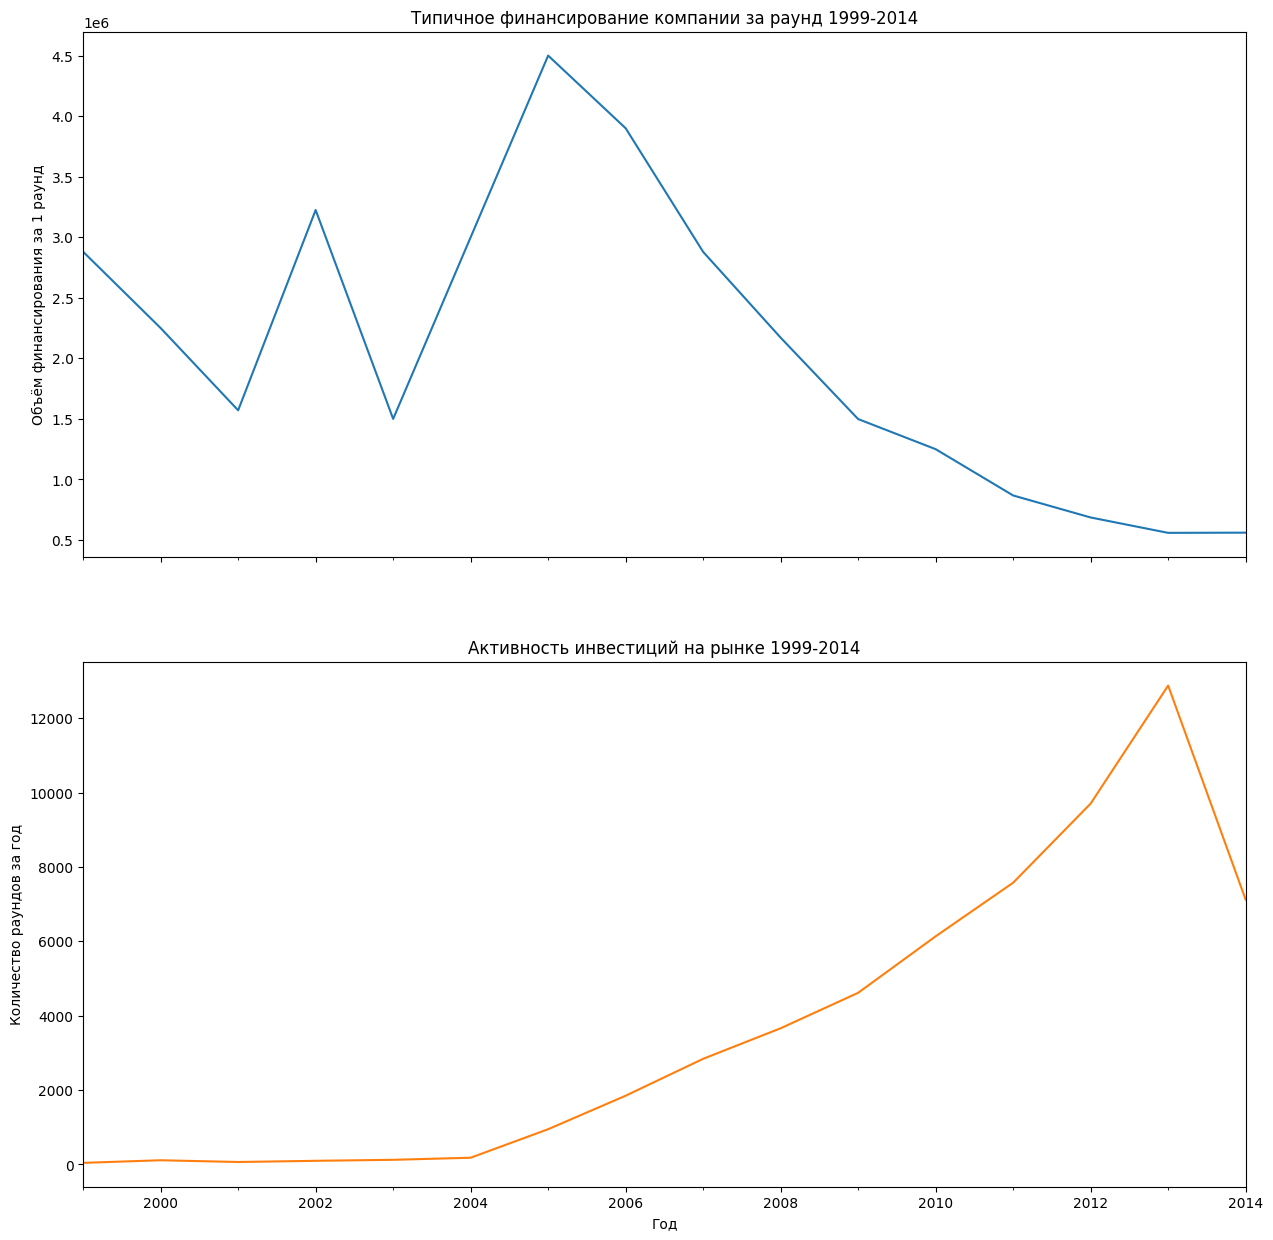

In [207]:
df_filtered.insert(loc=42, column='usd_to_round', value=round(df_filtered.loc[:,'funding_total_usd']/df_filtered.loc[:,'funding_rounds'],2))
df_agg = df_filtered.groupby(df_filtered['mid_funding_at'].dt.to_period('Y')).agg({'usd_to_round':'median', 'funding_rounds':'sum'})
axes = df_agg.plot(kind='line', subplots=True, sharex=True, sharey=False, legend=False,
                   title=['Типичное финансирование компании за раунд 1999-2014', 'Активность инвестиций на рынке 1999-2014'], figsize=(15,15))
axes[0].set_ylabel('Объём финансирования за 1 раунд')
axes[1].set_ylabel('Количество раундов за год')
plt.xlabel('Год')
plt.show()

Типичный размер средств, собранных в рамках одного раунда, был максимальным в 2005 и достигал 4,5 миллиона долларов. С тех пор наблюдалось монотонное падение объёма инвестиций за раунд, и к 2013 году достиг уровня чуть больше 0,5 миллиона долларов, а в 2014 остался на этом же уровне.

По количеству раундов наблюдается следующая тенденция: c 2004 года начало увеличиваться количество раундов, достигнув максимума в 2013 году (более 12000 раундов за год), однако в 2014 количество раундов финансирования уменьшилось примерно до 7000.

В целом с 2004-2005 года наблоюдается тенденция к "порционному" финансированию, однако в 2014 эта тенденция снизилась.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составим сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберём из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразим, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у нас достаточно данных. Рассмотрим только массовые сегменты, а средние и нишевые исключим.

На основе графика сделаем вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [208]:
df_filtered.insert(loc=43, column='year', value=df_filtered['mid_funding_at'].dt.to_period('Y'))

In [209]:
df_filtered_mass = df_filtered.loc[(df_filtered['segment']=='mass')&(df_filtered['market']!='Unknown')]

In [210]:
pivot_invest = pd.pivot_table(
    df_filtered_mass,
    index=['market'],
    values='funding_total_usd',
    columns = 'year',
    aggfunc='sum')

In [211]:
market_invest_filtered = pivot_invest.loc[pivot_invest['2013']<pivot_invest['2014']]
market_invest_filtered

year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014
market,,,,,,,,,,,,,,,,
apps,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1310600.0,NaN,4300000.0,7219000.0,6123779.0,18374071.0,32601125.0,28868621.0,66237730.0
big data,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7780000.0,2452515.0,597375.0,39233297.0,60369158.0,86413341.0,78698922.0,79232600.0
design,NaN,NaN,NaN,NaN,NaN,NaN,9300000.0,707000.0,10800000.0,5944302.0,2150144.0,17239975.0,8899967.0,39630692.0,60958835.0,68988516.0
internet,NaN,10000000.0,NaN,1100000.0,NaN,10500000.0,1775000.0,5000.0,4495379.0,23412964.0,38195773.0,36657500.0,36859032.0,28288685.0,69732096.0,117830756.0
manufacturing,NaN,56659310.0,2368582.0,NaN,4269608.0,3000000.0,61770000.0,163957751.0,147726051.0,173054260.0,422862531.0,244329661.0,561639285.0,522205168.0,393936634.0,416332314.0
medical,NaN,24000000.0,NaN,NaN,NaN,NaN,11090000.0,20250000.0,2100000.0,28812744.0,11566200.0,25590338.0,28540962.0,44039600.0,64469424.0,175236064.0
real estate,250000.0,2500000.0,NaN,5275000.0,6292200.0,NaN,250000.0,2080000.0,33220000.0,46613100.0,38840213.0,37344608.0,20015128.0,77320857.0,92207655.0,115567364.0
saas,NaN,NaN,NaN,2000000.0,NaN,NaN,5240000.0,4791121.0,14652595.0,27226900.0,13536585.0,32609390.0,32223749.0,49699912.0,79576613.0,92807752.0
startups,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5010387.0,460700.0,2111966.0,19654403.0,12358782.0,18080552.0,41501837.0


Видим, что для построения графика достаточно данных начиная с 2008 года. Построим график динамики общего финансирования по сегментам рынка

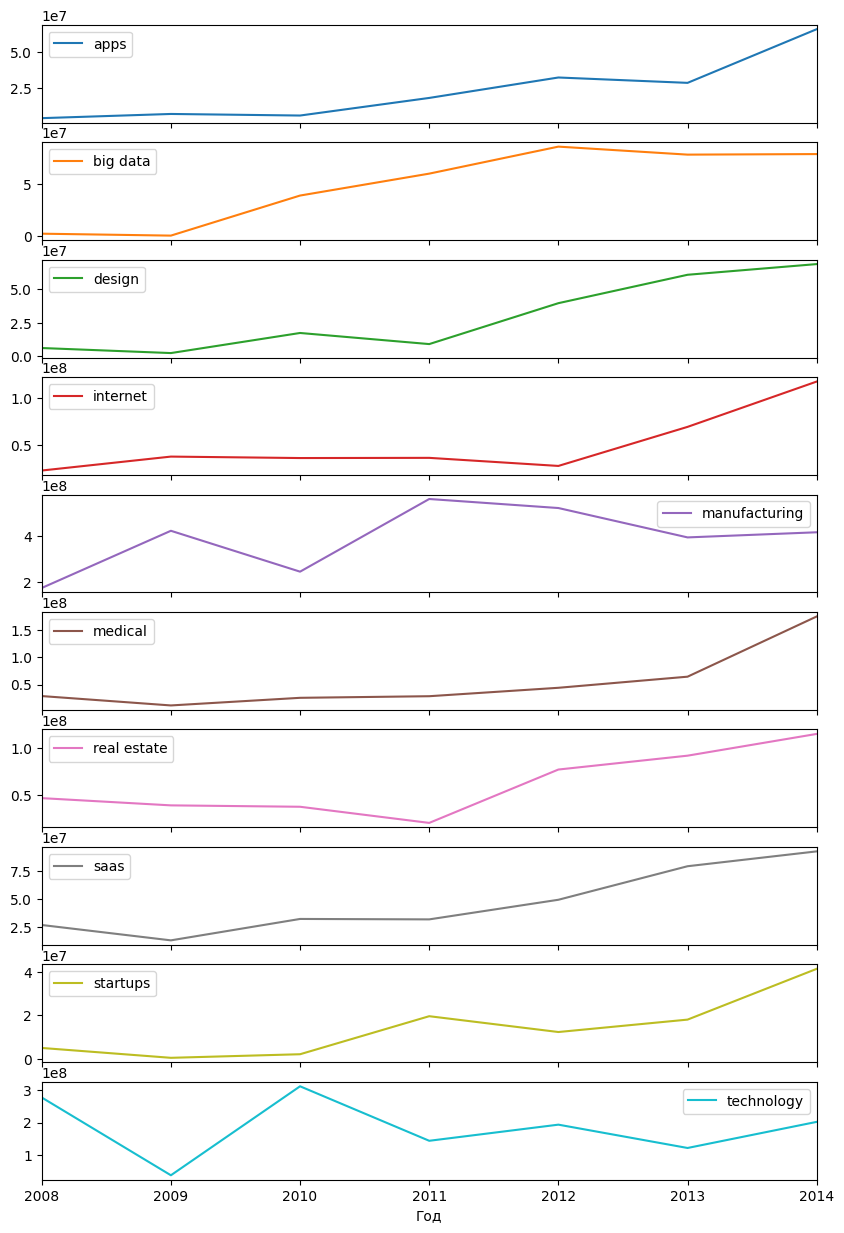

In [212]:
market_invest_filtered[['2008','2009','2010','2011','2012','2013','2014']].T.plot(kind='line', subplots=True, sharex=True, sharey=False, legend=True, figsize=(10,15))
plt.xlabel('Год')
plt.show()

В целом стабильный рост наблюдается во всех сегментах, кроме `big data`, `manufacturing`, `technology`. Однако наиболее быстрый рост наблюдается в следующих сегментах: `apps`, `internet`, `medical` и `startups`

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования
Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Наша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения заменим на пропуски.


In [213]:
df_returns = df_returns.reset_index()
df_returns['year'] = pd.to_datetime(df_returns['year'], format='%Y')
df_returns['year'] = df_returns['year'].dt.to_period('Y')

In [214]:
df_funding_type_years = df_filtered.groupby(df_filtered['year'])[funding_type].sum()
df_funding_type_years.reset_index()
df_total_type = df_funding_type_years.merge(df_returns, on = 'year', how = 'left')
df_total_share = pd.DataFrame(df_total_type['year'])
df_total_share['seed_share'] = round(1000000 * 100* df_total_type['seed_y']/(df_total_type['seed_x']+1e-60),2)
df_total_share['venture_share'] = round(1000000 * 100 * df_total_type['venture_y']/(df_total_type['venture_x']+1e-60),2)
df_total_share['equity_crowdfunding_share'] = round(1000000*100*df_total_type['equity_crowdfunding_y']/(df_total_type['equity_crowdfunding_x']+1e-60),2)
df_total_share['undisclosed_share'] = round(1000000*100*df_total_type['undisclosed_y']/(df_total_type['undisclosed_x']+1e-60),2)
df_total_share['convertible_note_share'] = round(1000000*100*df_total_type['convertible_note_y']/(df_total_type['convertible_note_x']+1e-60),2)
df_total_share['debt_financing_share'] = round(1000000*100*df_total_type['debt_financing_y']/(df_total_type['debt_financing_x']+1e-60),2)
df_total_share['angel_share'] = round(1000000*100*df_total_type['angel_y']/(df_total_type['angel_x']+1e-60),2)
df_total_share['grant_share'] = round(1000000*100*df_total_type['grant_y']/(df_total_type['grant_x']+1e-60),2)
df_total_share['private_equity_share'] = round(1000000*100*df_total_type['private_equity_y']/(df_total_type['private_equity_x']+1e-60),2)
df_total_share['post_ipo_equity_share'] = round(1000000*100*df_total_type['post_ipo_equity_y']/(df_total_type['post_ipo_equity_x']+1e-60),2)
df_total_share['post_ipo_debt_share'] = round(1000000*100*df_total_type['post_ipo_debt_y']/(df_total_type['post_ipo_debt_x']+1e-60),2)
df_total_share['secondary_market_share'] = round(1000000*100*df_total_type['secondary_market_y']/(df_total_type['secondary_market_x']+1e-60),2)
df_total_share['product_crowdfunding_share'] = round(1000000*100*df_total_type['product_crowdfunding_y']/(df_total_type['product_crowdfunding_x']+1e-60),2)
df_total_share = df_total_share.set_index('year')


In [215]:
for i in df_total_share.index:
    for column in df_total_share.columns:
        if df_total_share.loc[i,column]>1000:
            df_total_share.loc[i,column] = np.nan
df_total_share

,seed_share,venture_share,equity_crowdfunding_share,undisclosed_share,convertible_note_share,debt_financing_share,angel_share,grant_share,private_equity_share,post_ipo_equity_share,post_ipo_debt_share,secondary_market_share,product_crowdfunding_share
year,,,,,,,,,,,,,
1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000,99.65,16.89,0.00,69.70,0.00,61.86,26.70,0.0,0.00,27.11,0.00,2.59,0.00
2001,107.96,10.80,0.00,58.75,0.67,77.03,118.00,0.0,0.00,NaN,0.00,NaN,0.00
2002,62.97,68.23,0.00,60.89,NaN,22.34,113.67,0.0,20.13,113.33,0.00,NaN,0.00
2003,50.53,62.83,0.00,91.44,NaN,103.81,60.57,0.0,NaN,NaN,0.00,NaN,0.00
2004,54.85,83.70,0.00,52.76,NaN,43.97,83.35,0.0,NaN,NaN,0.00,NaN,0.00
2005,67.47,54.66,0.00,107.20,NaN,34.50,50.99,0.0,48.00,73.19,0.00,NaN,0.00
2006,92.54,34.37,20.36,75.94,16.63,80.38,67.49,0.0,93.55,NaN,0.00,NaN,0.00
2007,36.62,29.72,NaN,50.50,22.81,60.25,81.78,0.0,57.91,203.00,0.00,NaN,0.00


Построим график, на котором отобразим нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделаем вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

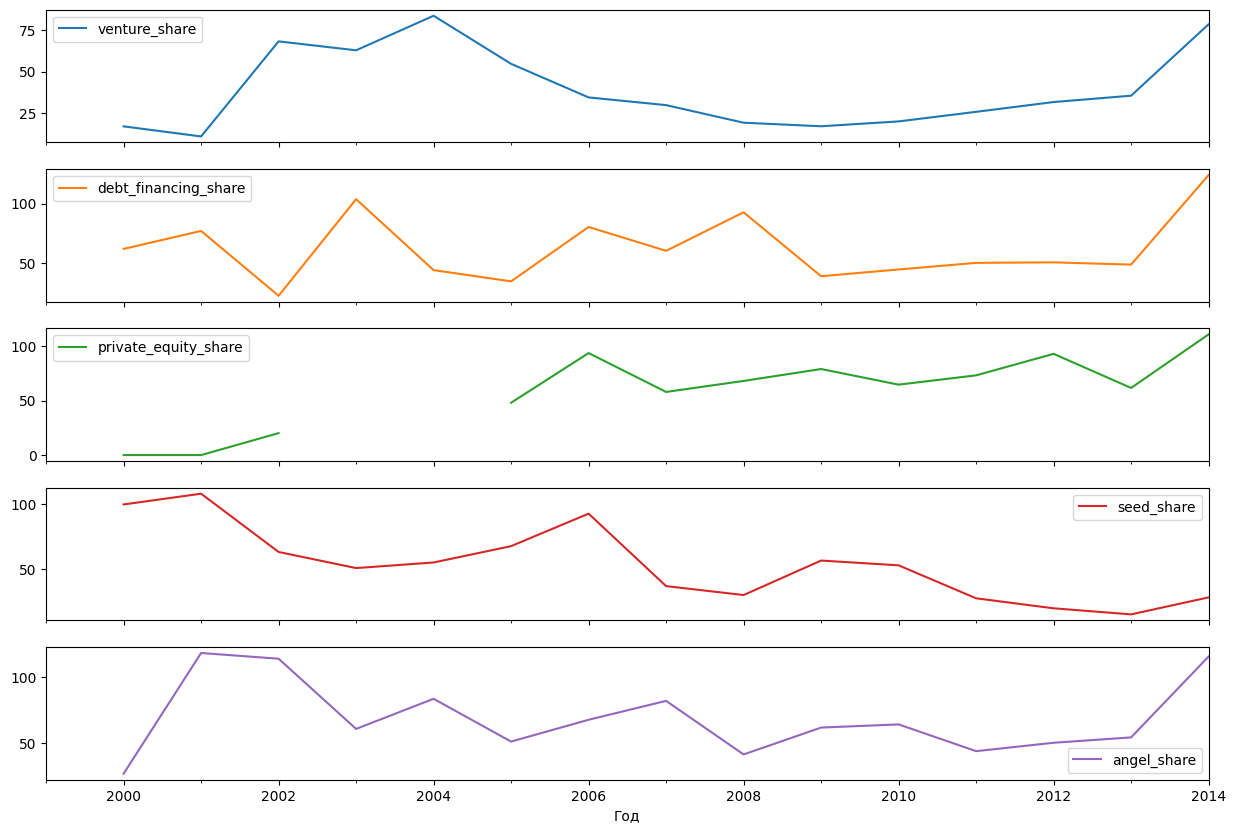

In [216]:
df_total_share[['venture_share','debt_financing_share', 'private_equity_share', 'seed_share', 'angel_share']].plot(kind='line', subplots=True, sharex=True, sharey=False, legend=True, figsize=(15,10))
plt.xlabel('Год')
plt.show()

Наиболее устойчивый рост доли возвратов наблюдается в следующих типах финансирования: венчурные инвестиции и прямые инвестиции. В долговом финансировании с 2009 наблюдался очень плавный рост, а в 2014 произошёл скачек вверх. Также с 2011 года наблюдается рост доли возвратов бизнес-ангелами, однако однозначно о стабильном росте в этом типе финансирования говорить пока рано. Из всех этих вариантов самым стабильным являются венчурные инвестиции.

## Шаг 5. Итоговый вывод и рекомендации
###Вывод
В ходе исследования были сделаны следующие шаги:
1. Знакомство с данными: загрузка и предобработка
2. Инжиниринг признаков
3. Работа с выбросами и анализ
4. Анализ динамики

В результате удалось сделать следующие выводы:
1. Самая популярная категория инвестиций - единичные, а самая большая по вложенному объему финансов - финансирование на протяжении менее года. Компании, финансируемые менее года самые непопулярные и в них вложено меньше всего финансов.
2. 73% сегментов рынка являются нишевыми, а количество средних и массовых рынков не сильно отличаются между собой. При этом в большей части нишевых сегментов рынка находятся 1-2 компании.
3. Типичные значения для финансирования компании в целом  не превышают 24,5 миллионов долларов, в среднем на одну компанию выделяется 2 миллиона долларов. Доля аномального финансирования   больше всего в следующих сегментах рынка: "real estate", "entertainment", "consulting".
4. Венчурные инвестиции - это самый популярный и наибольшой по объёму инвестиций тип финансирования, он занимает подавляющую часть рынка. На 2 месте по популярности являются инвестиции на посевной стадии.Хотя по объёму инвестиций этот тип финансирования тоже на 2 месте, это всего 6% от общего объёма инвестиций. На третьем месте долговые инвестиции.
5. В целом с 2004-2005 года наблюдается тенденция к "порционному" финансированию, когда количество раундов растет, а объём финансирования за один раунд уменьшается, однако в 2014 эта тенденция снизилась.
6. Наиболее быстрый рост инвестиций наблюдается в следующих сегментах: `apps`, `internet`, `medical` и `startups`.
7. Наиболее устойчивый рост доли возвратов наблюдается в следующих типах финансирования: венчурные инвестиции и и прямые инвестиции, а  в динамике долговых инвестиций произошёл скачок вверх после плавного роста, так что о стабильности говорить пока рано.
###Рекомендации
По результатам исследования можно дать следующие рекомендации:
* Привлекательными сегментами рынка для инвестиций являются следующие сегменты: `apps`, `internet`, `medical` и `startups`, там наблюдается наибольший рост инвестирования и не самая высокая доля аномальных инвестиций.
* Наиболее удачным типом финансирования при этом будут венчурные инвестиции,  в них наблюдается стабильный рост объёма возвратов, они самые популярные на рынке и занимают подавляющую долю по объёму инвестиций.

